In [1]:
#import some basic classes
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/AtmBlockPy/lib")
import BlockPlots as BP
import BlockTools as BT

In [2]:
%cd /Users/michelefilippucci/Data/ERA5/temperature
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/Users/michelefilippucci/Data/ERA5/temperature
ERA5_2m_temperature_day_r144x73_sfc_1979-2019.nc
ERA5_northem_2.5x2.5_t2m_monthly_jja_1940-2023.nc
ERA5_northem_2.5x2.5_t2m_monthly_jja_1940-2023_detrended.nc
ERA5_t2m_land_daily_2.5x2.5_jja_1940-2023.nc
ERA5_ta_day_r144x73_19790101-20191231.nc
ERA5_ta_mon_r144x73_19790101-20191231.nc
ERA5_ts_day_r144x73_19790101-20191231.nc
per_year


In [3]:
g = 9.80665  
  
#locations
reanalysis = "ERA5_northem_2.5x2.5_t2m_monthly_jja_1940-2023.nc"
output = "/Users/michelefilippucci/PLOTS/pres_exeter/temperature_climatology.png"
label = "jja"

In [4]:
ds = xr.load_dataset(reanalysis)

<xarray.DataArray 'zg_an' ()>
array(-0.1) <xarray.DataArray 'zg_an' ()>
array(0.45)


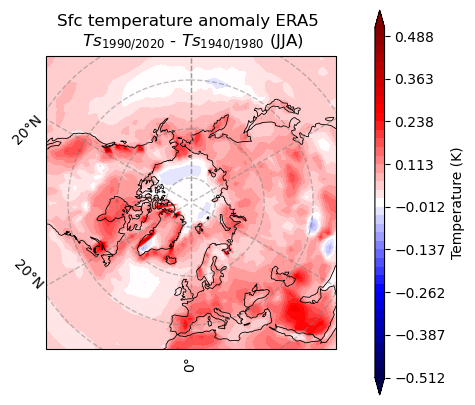

In [5]:
zg_stat = np.mean(ds["t2m"].loc["1950-06-01T09:00:00":"1980-08-31T09:00:00"], axis = 0)/9.81
zg_stat.name = "t2m"
zg_stat2 = np.mean(ds["t2m"].loc["1990-06-01T09:00:00":"2020-08-31T09:00:00"], axis = 0)/9.81
zg_stat2.name = "t2m"
diff = zg_stat2 - zg_stat
diff.name = "zg_an"
print(np.amin(diff),np.amax(diff))

lon = ds['longitude'].values
lon = np.append(lon,180)
lat = ds['latitude']
diff = cutil.add_cyclic_point(diff)

fig,ax = plt.subplots(nrows=1,ncols=1,figsize=(5,5),subplot_kw={'projection':ccrs.AzimuthalEquidistant(central_latitude=90)})
extent =[-180,180,30,90]
ax.set_extent(extent, ccrs.PlateCarree())
ax.coastlines(linewidth = 0.6)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')

gl.top_labels=False
gl.right_labels=False
cont = ax.contourf(lon,lat,diff,
                      np.arange(-0.5125,0.52,0.025),
                      extent=[0,90,-180,180],
                      extend = 'both',
                      transform = ccrs.PlateCarree(),
                      cmap = "seismic")

ax.set_title('Sfc temperature anomaly ERA5 \n $Ts_{1990/2020}$ - $Ts_{1940/1980}$ (JJA)')

cbar = plt.colorbar(cont, orientation='vertical',label="Temperature (K)",pad=0.1, aspect=40)

plt.show()
fig.savefig(output,dpi=300)


# 